In [1]:
import torch
from torchvision.transforms.functional import to_tensor
from PIL import Image
from SIM2TVFlowPyTorch import TV_enhancing
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["image.cmap"] = "gray"

device = "cpu"

In [2]:
# "spiral" "monalisa" "retina"
test = "monalisa"

In [3]:
Or = 16

match test:
    case "spiral":
        ground_truth = to_tensor(Image.open("spiral.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noisy = to_tensor(Image.open("noisyspiral.tif").convert("I"))[0].to(dtype=torch.float, device=device) / 255.**2
        scales = 4
        cut_freq = 0.5
        ξ = 0.51 
        t = 0.07

    case "monalisa":
        ground_truth = to_tensor(Image.open("monalisa.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noisy = to_tensor(Image.open("noisymonalisa.tif").convert("I"))[0].to(dtype=torch.float, device=device) / 255.**2
        scales = 4
        cut_freq = 0.25
        ξ= 0.21 
        t= 0.047 
        # Alternatively, if you want the same cut_freq as in 
        # spiral, then 
        #cut_freq = 0.5
        #ξ= 0.21 
        #t= 0.047 

    # In this case the noise in the image is very high
    case "retina":
        ground_truth = to_tensor(Image.open("test.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noise = 0.2 * 1. * torch.randn(ground_truth.shape, device=device)#, (2., 2.)
        noisy = torch.clip(ground_truth + noise, 0., 1.)

        scales = 4
        cut_freq = 0.25
        ξ= 0.15
        t= 0.05


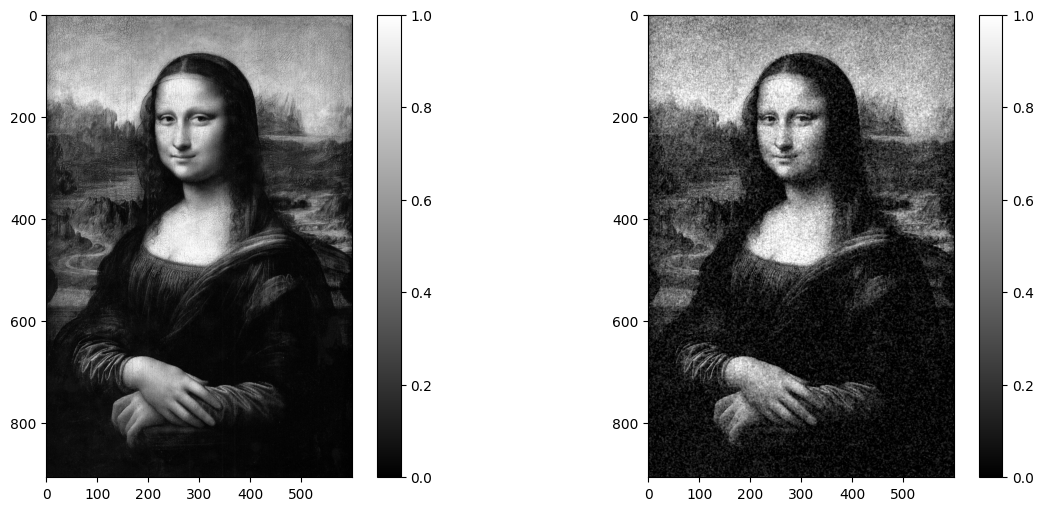

In [4]:

fig, ax = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
cbar = ax[0].imshow(ground_truth.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0])
cbar = ax[1].imshow(noisy.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[1]);

In [5]:
from stPyr import SteerablePyramid

stp = SteerablePyramid(noScales=scales, noOrientations=Or,  cut_freq=cut_freq, decimate=False, a=2.0)

def denoise(noisy, λ, ξ, t):

    with torch.no_grad():   
        Wx, WxLow = stp(noisy[None, None].clone())
    
    U_enhanced = []
         
    U = torch.stack(Wx)
    U = U.squeeze(1)
    print(U.shape)

    G_inv = ( (ξ**-2), (ξ**-2), 1., 0.0) # metric to use to define gradients.
    U = TV_enhancing(λ * U, t, G_inv, 2.0, 1., 0.5, 0.5) / λ


    U_enhanced = [
        U[s].unsqueeze(0)
        for s in range(U.shape[0])
    ]

    rec = stp.transpose(U_enhanced, WxLow).detach()
    return(rec[0,0])


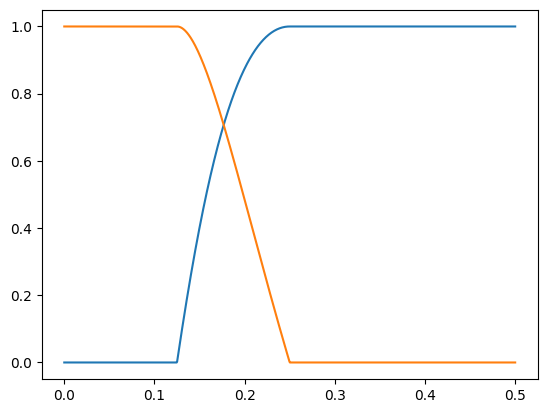

In [6]:
import numpy as np

# This code shows the 
x = torch.linspace(0, 0.5, 1000)
low, high = stp.stf[0].scales(x)

plt.plot(x, low.detach().cpu() )
plt.plot(x, high.detach().cpu() )
plt.show()

Recon error tensor(7.7123e-14)


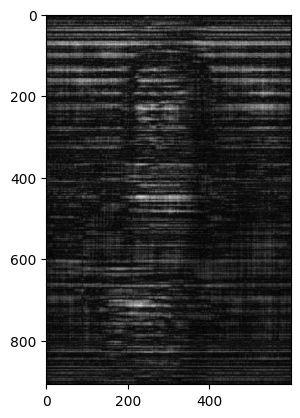

In [7]:
# Testing the reconstruction of the transform
with torch.no_grad():   
    Wx, WxLow = stp(noisy[None, None].clone())

rec = stp.transpose(Wx, WxLow)

print("Recon error %s"%(( rec-noisy)**2).mean() )
plt.imshow( (rec-noisy).abs()[0,0] )
plt.show()


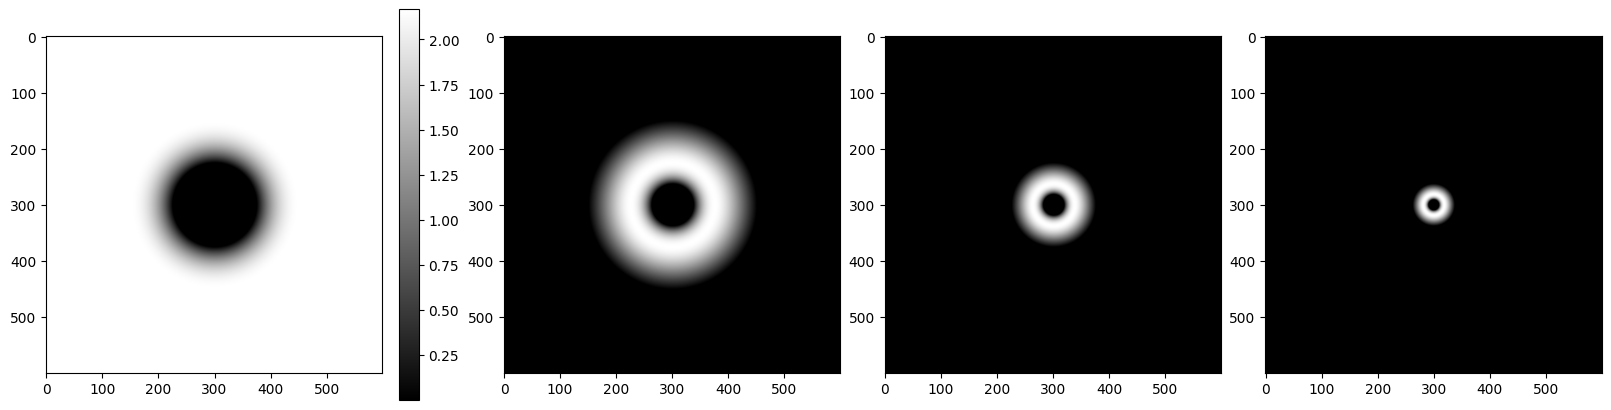

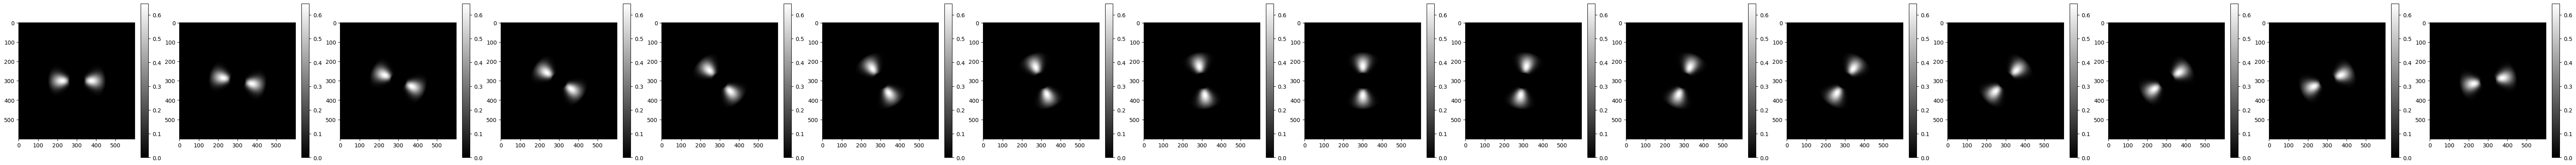

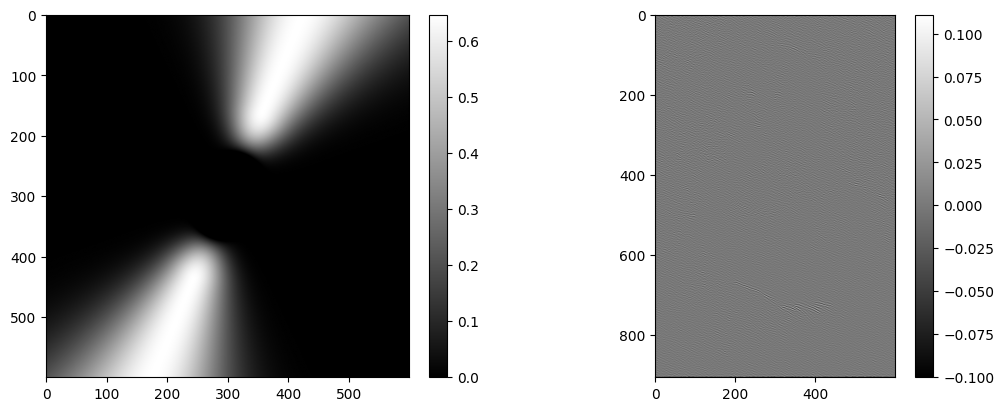

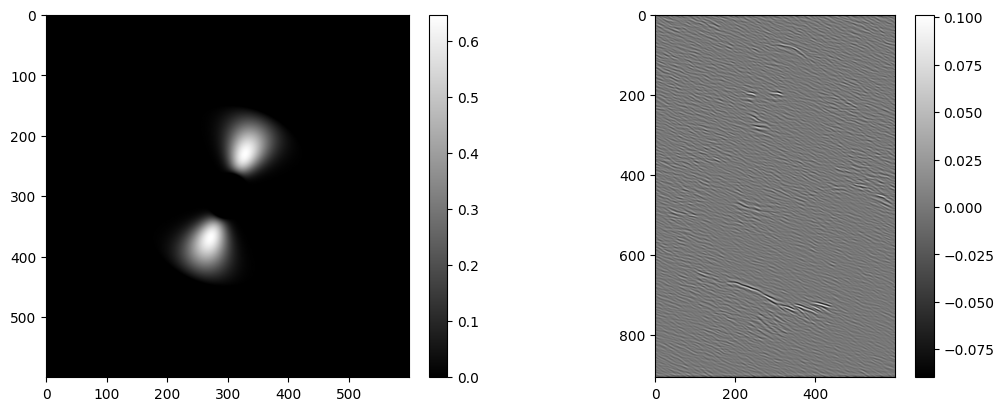

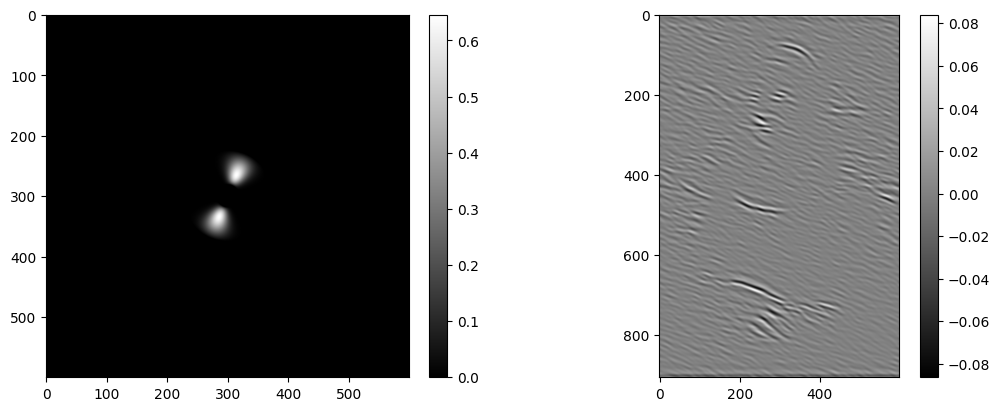

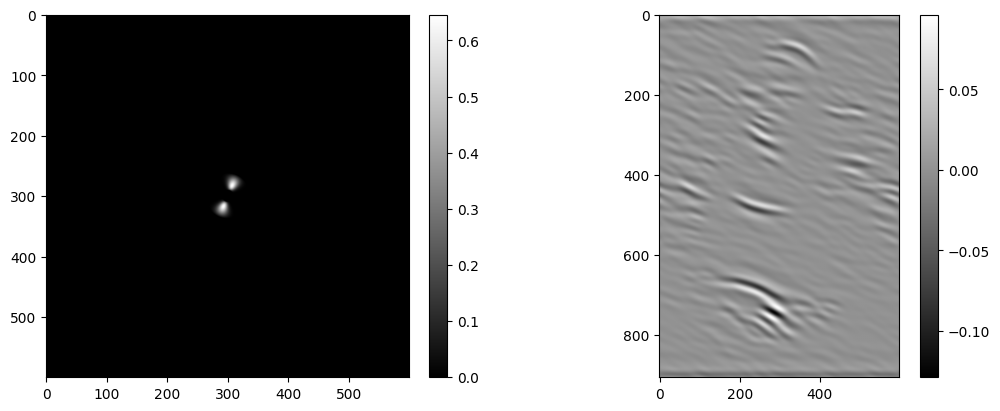

In [8]:
# Displaying the bands
# This is the orientation index

# Displaying also the "doughnut" in Fourier
K=10

# Testing reconstruction
H, W = ground_truth.shape
n = min(H, W)
dirac = torch.zeros((1,1,n,n),device=device, requires_grad=False)
dirac[0,0,n//2,n//2] = 1
with torch.no_grad():
    Wx_ir, WxLow_ir = stp(dirac)


# Showing the full "Doughnut" of each scale
fig, ax = plt.subplots(1, len(Wx_ir), figsize=(4*len(Wx_ir), 4), layout="constrained")
for i, Wx_s in enumerate(Wx):
    WF = torch.fft.fftshift( torch.fft.fft2( torch.fft.ifftshift(Wx_ir[i]) )).abs()
    cbar = ax[i].imshow( torch.sum(WF[0], dim =0).cpu())
fig.colorbar(cbar, ax=ax[0])
plt.show()


which_scale = 1
fig, ax = plt.subplots(1, Wx_ir[0].shape[1], figsize=(4*Wx_ir[0].shape[1], 4), layout="constrained")
# Showing the response at every scale
for i in range(Wx_ir[0].shape[1]):
    WF = torch.fft.fftshift( torch.fft.fft2( torch.fft.ifftshift(Wx_ir[which_scale][0,i]) )).abs()
    # This is one band at index K
    cbar = ax[i].imshow(WF.cpu())
    fig.colorbar(cbar, ax=ax[i])
plt.show()


# Showing the response at every scale
for i, Wx_s in enumerate(Wx):
    WF = torch.fft.fftshift( torch.fft.fft2( torch.fft.ifftshift(Wx_ir[i]) )).abs()
    # This is one band at index K
    fig, ax = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    cbar = ax[0].imshow(WF[0, K].cpu())
    fig.colorbar(cbar, ax=ax[0])
    cbar = ax[1].imshow(Wx_s[0,K].cpu())
    fig.colorbar(cbar, ax=ax[1]);
    plt.show()


In [9]:
λ = 50 # For some reason this helps with numerical stability 🤔
#rec = denoise(noisy.clone(), λ, ξ=0.38, t=0.15)

rec = denoise(noisy.clone(), λ, ξ, t)

torch.Size([4, 16, 907, 600])


  0%|          | 0/15 [00:00<?, ?it/s]

PSNR
tensor(27.8686)


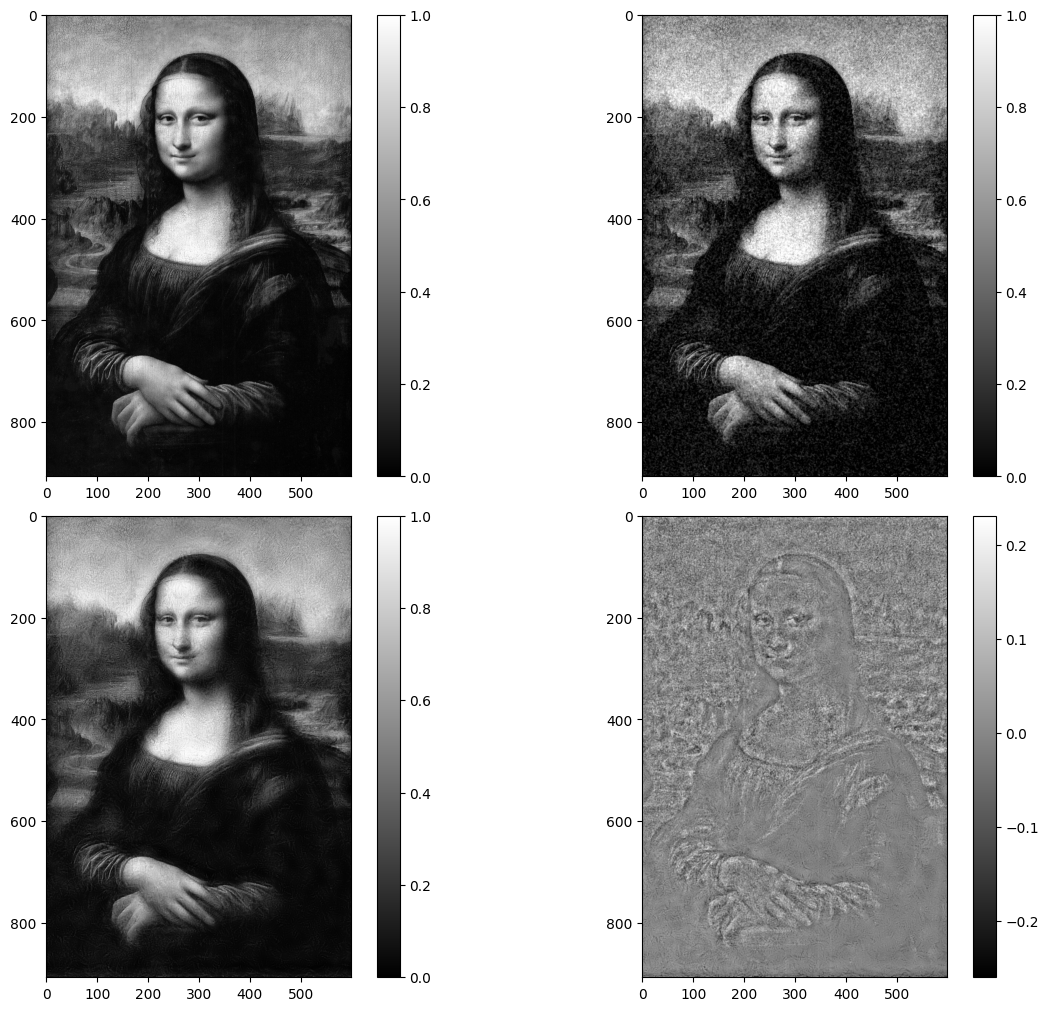

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")
cbar = ax[0, 0].imshow(ground_truth.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0, 0])
cbar = ax[0, 1].imshow(noisy.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0, 1])
cbar = ax[1, 0].imshow(torch.clip(rec, 0., 1.).cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[1, 0])
cbar = ax[1, 1].imshow((ground_truth - torch.clip(rec, 0., 1.)).cpu())
fig.colorbar(cbar, ax=ax[1, 1]);

psnr = -10*torch.log10( ((ground_truth - torch.clip(rec, 0., 1.)).cpu()**2).mean() )
print("PSNR")
print(psnr)

In [11]:
import numpy as np


def make_callback(args):
    def callback(xk):
        f = loss(xk, *args)
        print(f"loss={f:.6f}")
        print(f"x={xk}")
    return callback


def callback(xk, *args):
    func = loss(xk, *args)
    print(f"x = {xk}, loss = {func}")

def loss(x, *args):
    """ loss
        Description:

            This function is employed for finetuning of the PnP model
        Inputs:
            * x: Parameters to be optimized, in the case of PnP is a mixture
                component \gamma and the threshold level sigma
            * args: Additional optimizaton arguments
                * cnn

    """
    noisy, ground_truth, λ = args
    #ts = 10**x

    # For some reason it works better to make the search space in 
    # log scale. After the optimization is finished make 2**optimizer.x
    ξ = 2**x[0] # Link between spatial and orientational dimensions.
    t = 2**x[1]

    rec = denoise(noisy, λ, ξ, t)
        
    mse =  ((ground_truth - rec)**2).mean().item()
    return( mse )





<>:23: SyntaxWarning: invalid escape sequence '\g'
<>:23: SyntaxWarning: invalid escape sequence '\g'
C:\Users\s142021\AppData\Local\Temp\ipykernel_31796\1543247786.py:23: SyntaxWarning: invalid escape sequence '\g'
  component \gamma and the threshold level sigma


In [12]:
# Let's optimize the value of sig for the deblurring task

from scipy.optimize import minimize


ep = 0.25
λ = 50

x0 = np.ones( 2 )
x0[0] = 0.34 # epsilon 
x0[1] = 0.08 # t
x0 = np.log2( x0 )

options = {"disp":True,  "maxiter":20, "maxfev": 40, "fatol":1.0e-3, "xatol": 0.005}
args = (noisy, ground_truth, λ) 
optimizer = minimize(loss, x0=x0, args=args,
                        method='Nelder-Mead',  options=options, callback=make_callback(args))

torch.Size([4, 16, 907, 600])


  0%|          | 0/10 [00:00<?, ?it/s]

torch.Size([4, 16, 907, 600])


  0%|          | 0/11 [00:00<?, ?it/s]

torch.Size([4, 16, 907, 600])


...

  0%|          | 0/13 [00:00<?, ?it/s]

torch.Size([4, 16, 907, 600])


  0%|          | 0/11 [00:00<?, ?it/s]

C:\Users\s142021\AppData\Local\Temp\ipykernel_31796\1543247786.py:23: SyntaxWarning: invalid escape sequence '\g'
  component \gamma and the threshold level sigma


KeyboardInterrupt: 

In [13]:
optimizer

NameError: name 'optimizer' is not defined

In [ ]:
2**optimizer.x

In [ ]:
4.57
3.00